In [54]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
selection = data.selectionner(
    sources=("12kDE", "12kFE", "Normal"),
    canaux={"12kDE": ("DE",), 
            "12kFE": ("FE",), 
            "Normal": ("DE","FE")},
)

In [56]:
# Importation des données sélectionnées et ajout des indicateurs temporels et spectraux
table = features.construire_table(selection, data.charger)

In [57]:
# Visu dataset
# table.iloc[70:100, :15]
table[table["canal"] == "FE"]

# display(table.groupby(["source", "classe", "canal"]).size().unstack())
# table.defaut.unique()

,fichier,fenetre,rpm,canal,numero,source,fs,defaut,position_OR,diametre_mils,...,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF,f_pic,classe
101,Normal_L0,0,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001018,0.006267,0.005233,0.006086,0.203094,0.285649,0.133188,0.378069,60.058594,Sain
102,Normal_L0,1,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001319,0.004294,0.006015,0.006202,0.154014,0.332968,0.194814,0.318204,60.791016,Sain
103,Normal_L0,2,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000574,0.007760,0.007006,0.005637,0.067372,0.160511,0.171577,0.600541,60.058594,Sain
104,Normal_L0,3,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000867,0.003905,0.011645,0.013029,0.251415,0.253171,0.209546,0.285868,30.761719,Sain
105,Normal_L0,4,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000781,0.008527,0.009871,0.011672,0.199272,0.142502,0.173827,0.484400,31.494141,Sain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4712,12kFE_OR021at6_L0,45,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.063823,0.056750,0.586948,0.669555,0.109431,0.541788,0.284245,0.064536,30.029297,OR021
4713,12kFE_OR021at6_L0,46,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.028864,0.029306,0.318542,0.330890,0.199736,0.660242,0.098169,0.041853,91.552734,OR021
4714,12kFE_OR021at6_L0,47,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.022011,0.019165,0.560075,0.656948,0.174760,0.494200,0.310677,0.020363,30.029297,OR021
4715,12kFE_OR021at6_L0,48,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.047168,0.030995,0.583986,0.674855,0.110190,0.549091,0.306058,0.034660,30.029297,OR021


In [58]:
# Preparation pour le modeling
#| label: preparation-modeling
#| code-summary: "Split par fichier + standardisation"
#| tbl-cap: "Répartition des fichiers entre apprentissage et test."

COLONNES_INDICATEURS = indicateurs.COLONNES_INDICATEURS
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling(table, COLONNES_INDICATEURS)
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target="defaut")
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="FE", canal_test="DE", target="defaut")

print("##########################################")
print("######### Table d'apprentissage ##########")
print("##########################################")
print("1. Split Train => DE, Test => FE")
print("2. Répartition des classes du train")

# Équilibre UNIQUEMENT le train (le test reste complet)
X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

print("##########################################")
print("############### Features #################")
print("##########################################")
X_train.head()

##########################################
######### Table d'apprentissage ##########
##########################################
1. Split Train => DE, Test => FE
2. Répartition des classes du train


,train,test
defaut,,
B,300,601
IR,300,601
OR,300,603
Sain,300,706


##########################################
############### Features #################
##########################################


,RMS,Pic,Crete,Kurtosis,amp_BPFI_1,amp_BPFI_2,amp_BPFI_3,amp_BPFO_1,amp_BPFO_2,amp_BPFO_3,...,amp_BSF_2,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF,f_pic
982,-0.751674,-0.805841,-0.940532,-0.685621,-0.836519,-0.797462,-0.780522,-0.475496,-0.457580,-0.473636,...,-0.715269,-0.881317,-0.518023,-0.630844,-0.590992,-1.113048,-0.778439,-1.160112,1.908087,3.278160
182,-0.658169,-0.770109,-1.077345,-0.761624,-0.821678,-0.868833,-0.766594,-0.464158,-0.462951,-0.502738,...,-0.733009,-0.840259,-0.556962,-0.603785,-0.568246,-0.730632,0.077522,0.098300,0.471311,-0.435728
178,-0.660224,-0.718686,-0.655772,-0.723805,-0.812465,-0.821116,-0.804156,-0.456787,-0.440182,-0.477694,...,-0.745651,-0.844747,-0.563355,-0.590154,-0.557423,-0.533882,0.539609,-0.297943,0.177458,-0.435728
510,-0.750744,-0.842330,-1.304518,-0.728073,-0.823054,-0.801898,-0.718895,-0.465022,-0.456975,-0.477667,...,-0.805176,-0.896378,-0.525379,-0.668833,-0.617690,-0.849548,-0.136507,-0.431317,0.943447,3.342750
823,-0.742233,-0.799035,-0.926373,-0.742581,-0.825147,-0.725243,-0.702629,-0.470671,-0.466744,-0.452743,...,-0.785359,-0.893058,-0.563732,-0.645642,-0.602305,-0.679202,-0.318600,0.266226,0.627957,3.314043


In [59]:
#| label: regression logistique
from sklearn import linear_model

logreg = linear_model.LogisticRegression(max_iter=500, random_state=24)
logregb = linear_model.LogisticRegression(max_iter=500, random_state=24, class_weight="balanced") ##  >> Pour gérer le déséquilibre de classes

logreg.fit(X_train, y_train)
logregb.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_predb = logregb.predict(X_test)
cm = pd.crosstab(y_test, y_pred, rownames=['Classe réelle'], colnames=['Classe prédite'])
cmb = pd.crosstab(y_test, y_predb, rownames=['Classe réelle'], colnames=['Classe prédite'])

=== LogReg FE→DE ===
Accuracy          : 0.911
Balanced accuracy : 0.907
F1-macro          : 0.905

Rapport par classe :
              precision    recall  f1-score   support

           B       0.74      0.97      0.84       601
          IR       0.97      1.00      0.98       601
          OR       1.00      0.66      0.80       603
        Sain       1.00      1.00      1.00       706

    accuracy                           0.91      2511
   macro avg       0.93      0.91      0.90      2511
weighted avg       0.93      0.91      0.91      2511



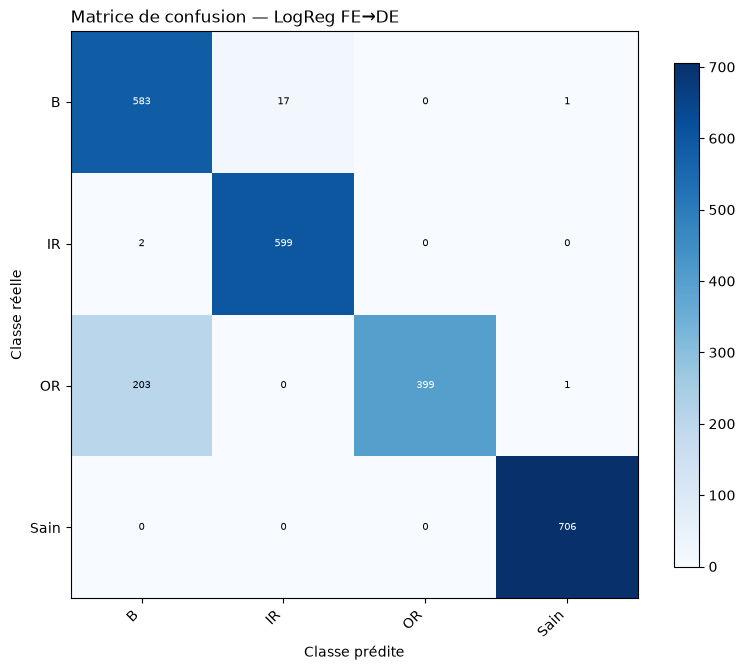

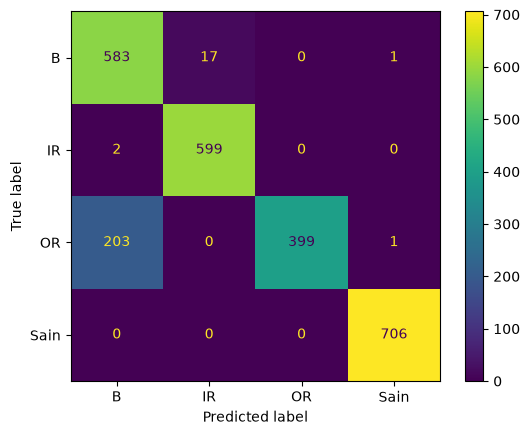

In [ ]:
models.evaluer_modele(y_test, y_pred, classes=logreg.classes_, titre="LogReg FE→DE")